# 5 seeds were trained based on the evaluation of the cql alpha sweep contained in evaluate_cql_alpha_sweep.ipynb

In [2]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.action_distribution_sweep as action_dist
import src.rl.clinician_baseline as clin_baseline
import src.rl.reward_by_vaso_match as vaso_match
import src.rl.dose_histogram_by_alpha as dose_hist
import src.rl.inspect_fluid_params as raw_params
import src.rl.check_std_floor as std_check
import src.rl.diagnose_fluid_spike as spike_diag
import src.rl.plot_fluid_two_population as fluid_pop
import src.rl.plot_fluid_dose_severity_heatmaps as heatmap_diag
import src.rl.final_model_selection as final_select
import src.rl.advantage_distributions_by_seed as adv_dist
import src.rl.occupancy_by_seed as occ_seed
import src.rl.shape_dose_overlap as shape_overlap
import src.rl.dose_response_shapes as analyze_nm

# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/cql_alpha_sweep"
# os.makedirs(SAVE_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

basic_q_health_score_model_dir = os.path.join(basic_q_dir, "health_score_change_only")
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_health_score_model_dir)

basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_202

In [4]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )

    # print cql value for this model
    print(f"Loaded CQL health-score model from {model_dir}, cql_alpha={health_score_hyperparams['cql_alpha']}")

    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))


Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-235751_073683e4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-225924_24f16bd0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-232805_87a9aaa

# Load data

In [5]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [6]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675
Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615
=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569
=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [7]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# standard deviation
### "seed 4 showed a degenerate vaso magnitude std distribution (bimodal at clamp extremes); this had negligible practical effect given vaso's near-zero firing rate for this seed, but is noted as a seed-level irregularity."

Floor std = 0.1353, Ceiling std = 2.7183

Seed    Drug        mean     std     min     max  median   %floor   %ceil
-----------------------------------------------------------------------
1       Fluid     0.7548  0.5652  0.1982  2.7183  0.5828     0.0%    4.6%
1       Vaso      0.7637  0.2906  0.4735  2.7183  0.6605     0.0%    0.3%
2       Fluid     0.7164  0.5346  0.2005  2.7183  0.5360     0.0%    4.0%
2       Vaso      0.5793  0.1771  0.3010  1.7930  0.5267     0.0%    0.0%
3       Fluid     0.7475  0.5617  0.1767  2.7183  0.5945     0.0%    5.2%
3       Vaso      0.8154  0.4384  0.4172  2.7183  0.6710     0.0%    3.0%
4       Fluid     0.8077  0.6236  0.1814  2.7183  0.5960     0.0%    6.1%
4       Vaso      1.9080  1.0316  0.1353  2.7183  2.7183     7.6%   53.8%
5       Fluid     0.7952  0.6323  0.1929  2.7183  0.5953     0.0%    7.2%
5       Vaso      0.6683  0.3050  0.3487  2.7183  0.5507     0.0%    0.1%

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_wi

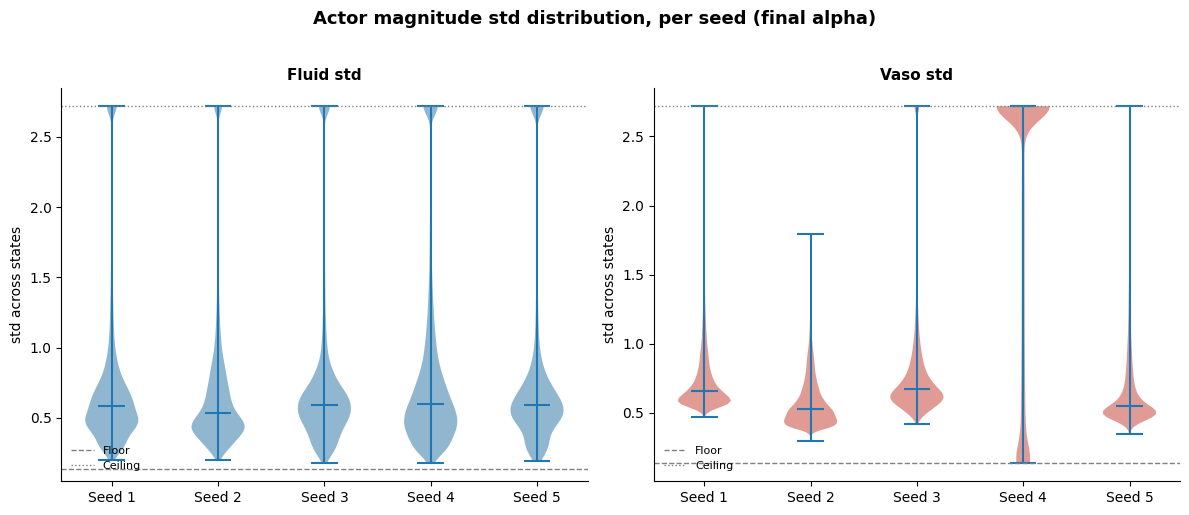

In [8]:
fig = std_check.plot_std_distributions_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    save_path=os.path.join(cql_model_dir, "std_distributions_by_seed_health_score.png"),
)
fig

"Co-occurrence of ceiling-saturated magnitude standard deviation and near-maximal fluid dosing

We tested whether the residual near-maximal (>0.9) fluid dose recommendations identified throughout this analysis co-occur with states where the actor's fluid magnitude standard deviation is saturated at its clamp ceiling, on the held-out test set, across all 5 final seeds. A meaningful and consistent association was present: 41–74% of high-dose states also showed ceiling-saturated magnitude std (mean ≈ 55%, seed 2 the notable outlier at 74%), while a smaller but still non-trivial 14–43% of ceiling-saturated states corresponded to a high-dose recommendation. This asymmetry indicates that magnitude-variance saturation is a broader phenomenon than the extreme-dose pathology specifically — most ceiling-saturated states do not in fact yield a near-maximal dose — but that a substantial minority-to-majority of the extreme-dose recommendations are accompanied by this internal saturation signature, consistent with both symptoms arising from a shared underlying instability in the actor's magnitude parameterization at these states, rather than being independent phenomena.

Given this partial but incomplete overlap, we do not consider magnitude standard deviation alone a sufficiently sensitive or specific signal to serve as a stand-alone clinical safety flag: using it in isolation would miss a substantial fraction of the problematic recommendations (those without ceiling-saturated std) while over-flagging a larger set of states where saturation is present but the resulting dose is unremarkable. We instead propose data-support (occupancy) at the recommended dose, evaluated per-recommendation against the training distribution stratified by patient severity, as the primary mechanism for flagging low-confidence recommendations to clinicians (Section [X]); the std/dose co-occurrence result reported here is presented as corroborating mechanistic evidence for the origin of the residual extreme-dose behavior, not as an alternative or additional clinical safeguard.

This association was directionally consistent but showed some variability across seeds and evaluation splits (e.g., seed 2's overlap fraction was 49.8% on the validation set and 74.2% on the held-out test set for the same trained model), consistent with sampling noise in these relatively small sub-populations rather than genuine seed-level instability."

In [9]:
for seed_idx, _ in enumerate(cql_health_score_fixed_alpha_models):
    print(f"Checking std dose co-occurrence for seed {seed_idx}...")
    ceiling_mask, high_dose_mask = std_check.check_std_dose_cooccurrence(
        cql_health_score_fixed_alpha_models[seed_idx],  # one seed at a time
        processors['test'],
        dim=0,  # fluid
    )

Checking std dose co-occurrence for seed 0...
Ceiling-std states: 5375 (4.61% of all states)
High-dose (>0.9) states: 2453 (2.10% of all states)
States that are BOTH: 1207
  Fraction of ceiling-std states that are ALSO high-dose: 22.5%
  Fraction of high-dose states that are ALSO ceiling-std: 49.2%
Checking std dose co-occurrence for seed 1...
Ceiling-std states: 4682 (4.01% of all states)
High-dose (>0.9) states: 1649 (1.41% of all states)
States that are BOTH: 681
  Fraction of ceiling-std states that are ALSO high-dose: 14.5%
  Fraction of high-dose states that are ALSO ceiling-std: 41.3%
Checking std dose co-occurrence for seed 2...
Ceiling-std states: 6058 (5.19% of all states)
High-dose (>0.9) states: 1334 (1.14% of all states)
States that are BOTH: 990
  Fraction of ceiling-std states that are ALSO high-dose: 16.3%
  Fraction of high-dose states that are ALSO ceiling-std: 74.2%
Checking std dose co-occurrence for seed 3...
Ceiling-std states: 7111 (6.10% of all states)
High-dose

# advantage

Computing advantage for seed 1/5...
    own-critic Q IQR (real clinician actions): 3.2691
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
    SARSA seed 4 Q IQR (real clinician actions): 1.0574
    SARSA seed 5 Q IQR (real clinician actions): 1.0174
Computing advantage for seed 2/5...
    own-critic Q IQR (real clinician actions): 2.8881
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
    SARSA seed 4 Q IQR (real clinician actions): 1.0574
    SARSA seed 5 Q IQR (real clinician actions): 1.0174
Computing advantage for seed 3/5...
    own-critic Q IQR (real clinician actions): 2.7309
    SARSA seed 1 Q IQR (real clinician actions): 0.9590
    SARSA seed 2 Q IQR (real clinician actions): 1.0164
    SARSA seed 3 Q IQR (real clinician actions): 0.9705
  

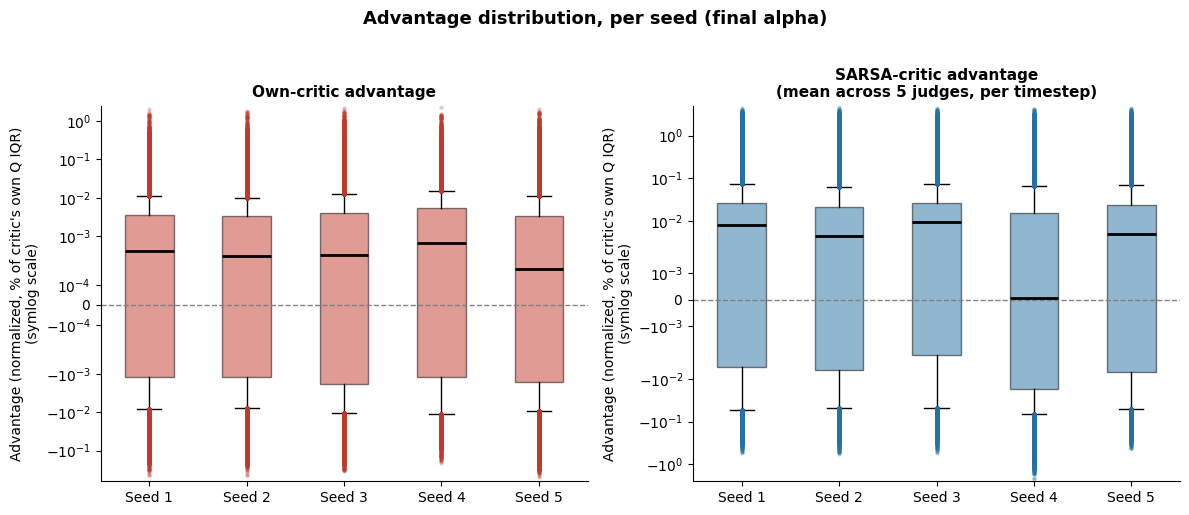

In [10]:
# reuse eval_cql's function directly, or import compute_model_advantage into this module's namespace
adv_dist.compute_model_advantage = eval_cql.compute_model_advantage

own_by_seed, sarsa_by_seed = adv_dist.compute_advantage_distributions_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    basic_q_health_score_models,
)

fig = adv_dist.plot_advantage_distributions_by_seed(
    own_by_seed, sarsa_by_seed,
    save_path=os.path.join(cql_model_dir, "advantage_distributions_by_seed_health_score.png"),
)
fig

# occupancy

Computing occupancy for seed 1/5...


  seed 1: 97.9% well-supported (min_count=10), median count=213
Computing occupancy for seed 2/5...
  seed 2: 98.7% well-supported (min_count=10), median count=287
Computing occupancy for seed 3/5...
  seed 3: 98.8% well-supported (min_count=10), median count=227
Computing occupancy for seed 4/5...
  seed 4: 93.0% well-supported (min_count=10), median count=213
Computing occupancy for seed 5/5...
  seed 5: 97.8% well-supported (min_count=10), median count=248
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/occupancy_by_seed_health_score.png


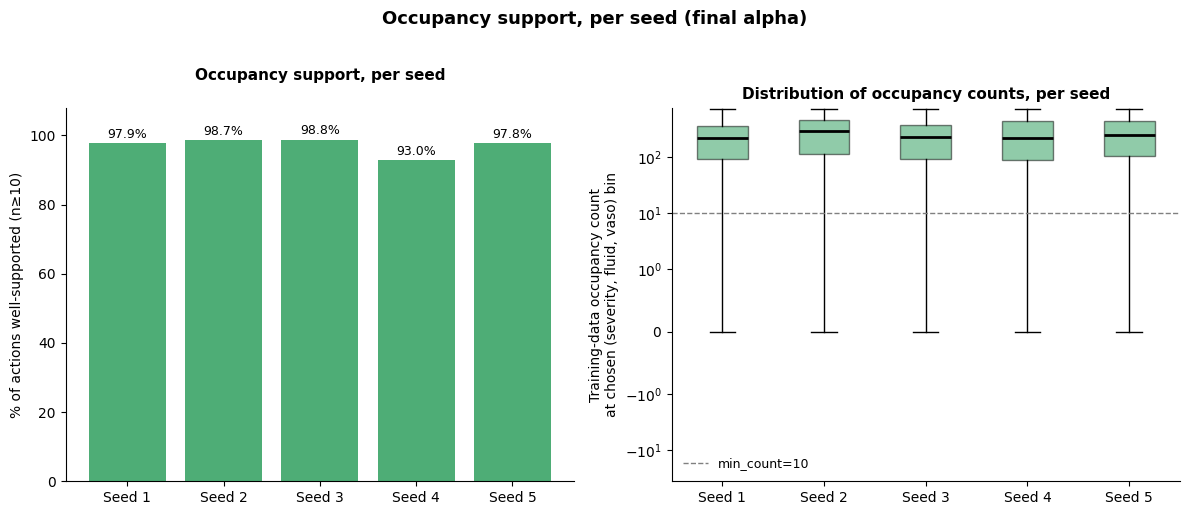

In [11]:
occ_seed.get_actor_actions = action_dist.get_actor_actions
occ_seed.compute_occupancy_support_of_actions = eval_cql.compute_occupancy_support_of_actions

support_frac_by_seed, counts_by_seed = occ_seed.compute_occupancy_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    test_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 200
)

fig = occ_seed.plot_occupancy_by_seed(
    support_frac_by_seed, counts_by_seed,
    save_path=os.path.join(cql_model_dir, "occupancy_by_seed_health_score.png"),
)
fig

# action distributions

seed 1/5: fluid[rate=99.9%, mean=0.4131, nonzero_mean=0.4135]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=99.6%, mean=0.4532, nonzero_mean=0.4549]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=99.4%, mean=0.3967, nonzero_mean=0.3993]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=100.0%, mean=0.5126, nonzero_mean=0.5129]  vaso[rate=28.7%, mean=0.0209, nonzero_mean=0.0727]
seed 5/5: fluid[rate=98.1%, mean=0.4554, nonzero_mean=0.4641]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score_test.png


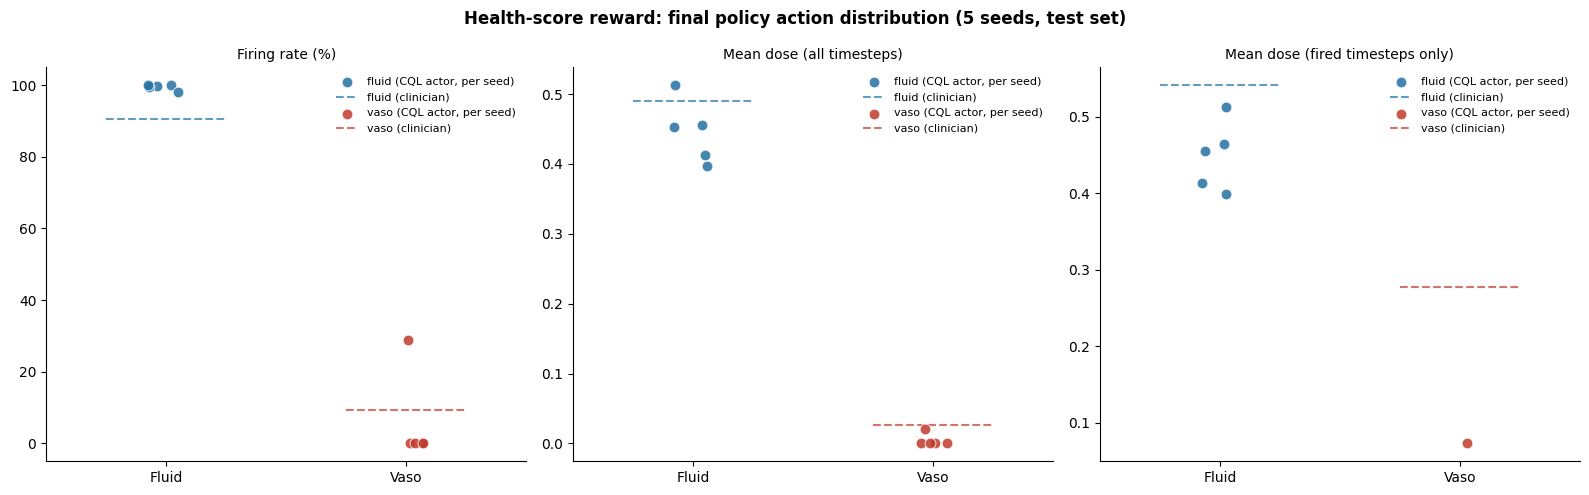

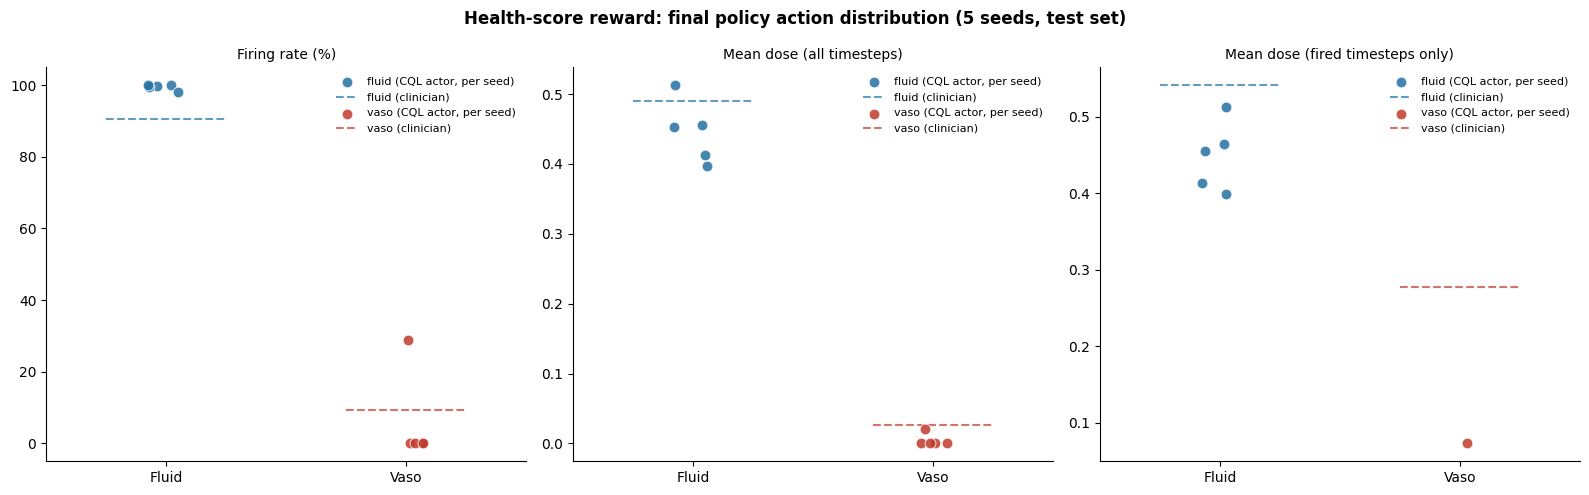

In [12]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score_test.png"),
)
fig_health_score

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=105578, mean=0.5415, std=0.1455, median=0.5658, p10=0.3484, p25=0.4731, p75=0.6289, p90=0.6960
  alpha=0: n=116542, mean=0.4135, std=0.2014, median=0.4202, p10=0.1340, p25=0.3002, p75=0.5174, p90=0.6611
  alpha=1: n=116236, mean=0.4549, std=0.1870, median=0.4650, p10=0.2172, p25=0.3573, p75=0.5680, p90=0.6679
  alpha=2: n=115915, mean=0.3993, std=0.1839, median=0.4136, p10=0.1476, p25=0.2898, p75=0.5055, p90=0.6179
  alpha=3: n=116605, mean=0.5129, std=0.2024, median=0.5023, p10=0.2806, p25=0.3913, p75=0.6426, p90=0.7668
  alpha=4: n=114466, mean=0.4641, std=0.2164, median=0.4689, p10=0.1749, p25=0.3407, p75=0.5972, p90=0.7369
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_5seeds.png


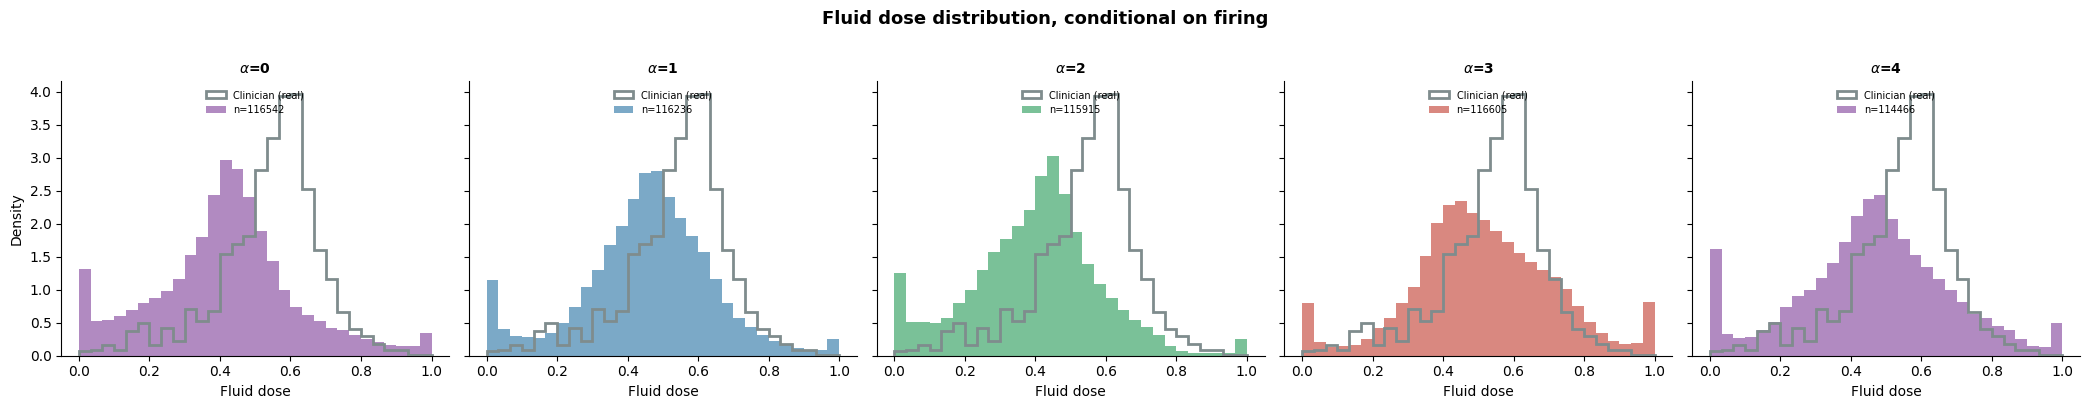

In [13]:
clinician_actions_test = processors['test'].rl_dataset["actions"]

# build a seed-keyed dict so plot_dose_histograms (originally alpha-keyed) works unchanged
cql_health_score_by_seed = {i: model_entry for i, model_entry in enumerate(cql_health_score_fixed_alpha_models)}

fig_fluid = dose_hist.plot_dose_histograms(
    cql_health_score_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    n_cols=5,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_5seeds.png"),
)

=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=10921, mean=0.2775, std=0.1371, median=0.2411, p10=0.1552, p25=0.1718, p75=0.3435, p90=0.4688
  alpha=0: no nonzero doses


/home/jake/miniconda3/envs/rl_env/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


  alpha=1: no nonzero doses
  alpha=2: no nonzero doses
  alpha=3: n=33522, mean=0.0727, std=0.0979, median=0.0200, p10=0.0002, p25=0.0010, p75=0.1190, p90=0.2169
  alpha=4: no nonzero doses
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_vaso_5seeds.png


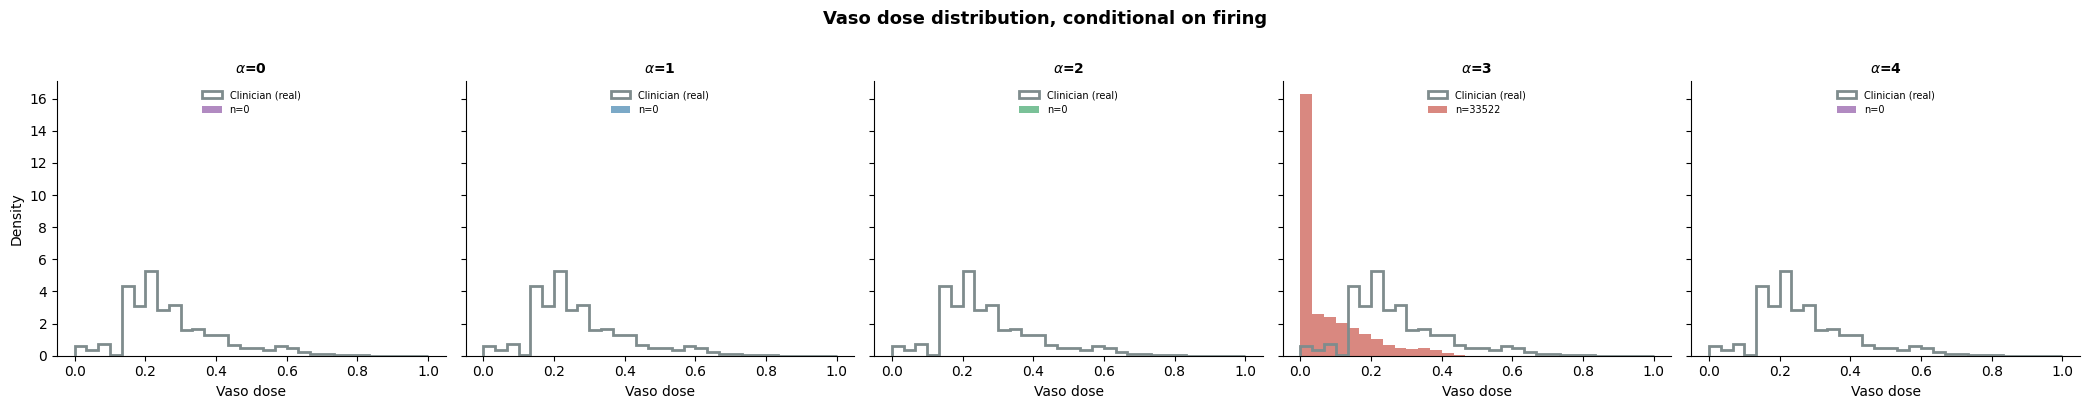

In [14]:
clinician_actions_test = processors['test'].rl_dataset["actions"]

# build a seed-keyed dict so plot_dose_histograms (originally alpha-keyed) works unchanged
cql_health_score_by_seed = {i: model_entry for i, model_entry in enumerate(cql_health_score_fixed_alpha_models)}

fig_fluid = dose_hist.plot_dose_histograms(
    cql_health_score_by_seed,
    processor=processors['test'],
    clinician_actions=clinician_actions_test,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    n_cols=5,
    save_path=os.path.join(cql_model_dir, "dose_histogram_vaso_5seeds.png"),
)

# dose response shape


=== Seed 0 ===
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid point 5/20 (value=0.211)...
    grid point 6/20 (value=0.263)...
    grid point 7/20 (value=0.316)...
    grid point 8/20 (value=0.368)...
    grid point 9/20 (value=0.421)...
    grid point 10/20 (value=0.474)...
    grid point 11/20 (value=0.526)...
    grid point 12/20 (value=0.579)...
    grid point 13/20 (value=0.632)...
    grid point 14/20 (value=0.684)...
    grid point 15/20 (value=0.737)...
    grid point 16/20 (value=0.789)...
    grid point 17/20 (value=0.842)...
    grid point 18/20 (value=0.895)...
    grid point 19/20 (value=0.947)...
    grid point 20/20 (value=1.000)...
[seed0] 46697 non-monotonic timesteps out of 116662 (40.0%)
[seed0]  of non-monotonic: 7.3% convex (U-shaped), 92.7% concave (inverted-U)
[seed0]  99.0% have a genuine interior vertex (rest are edge-dominated / not a true turning poi

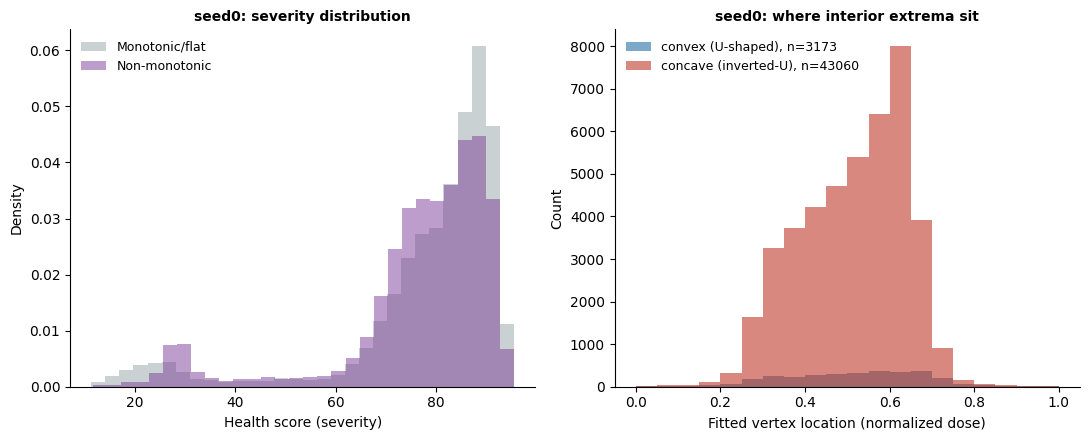

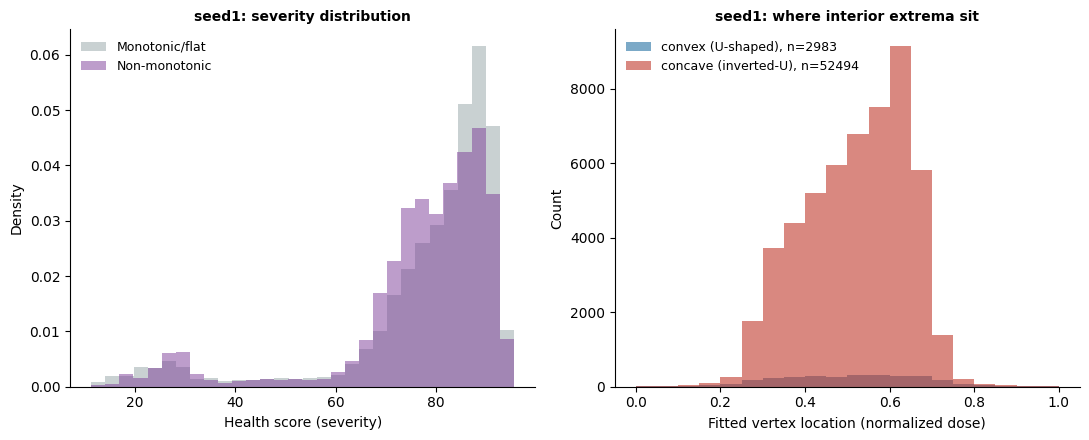

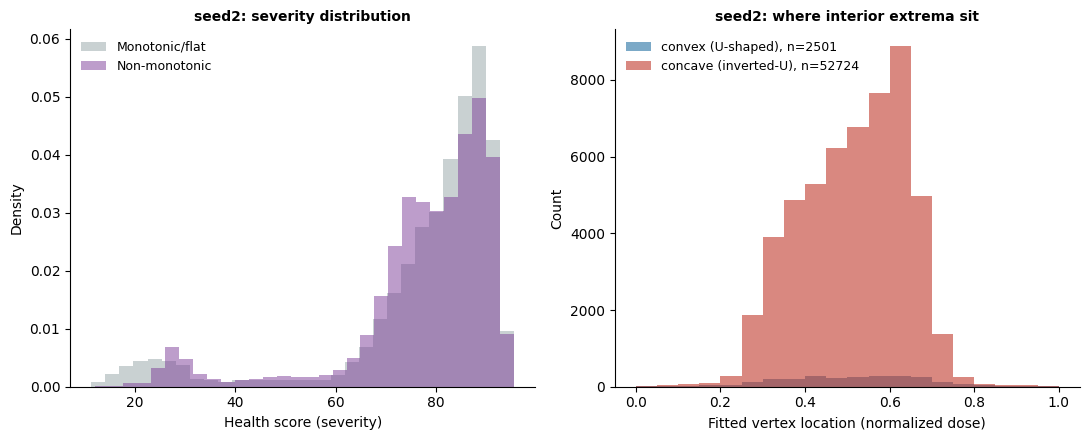

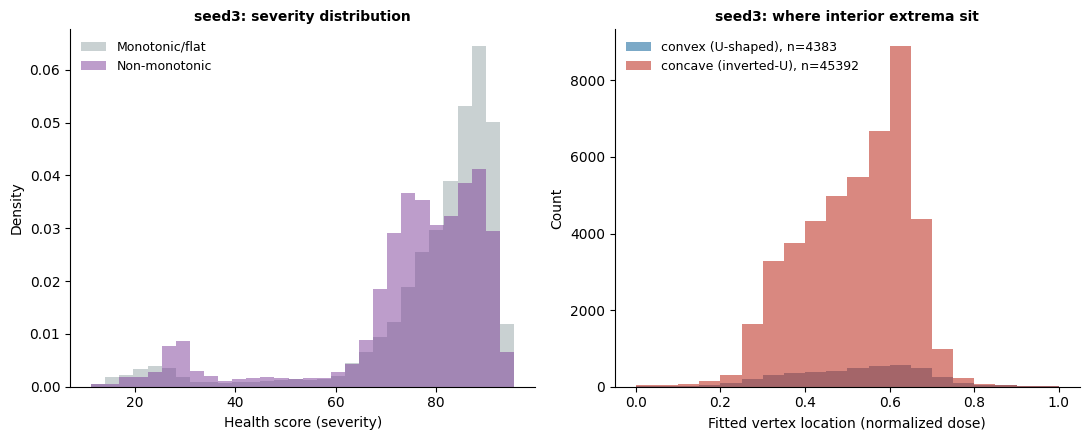

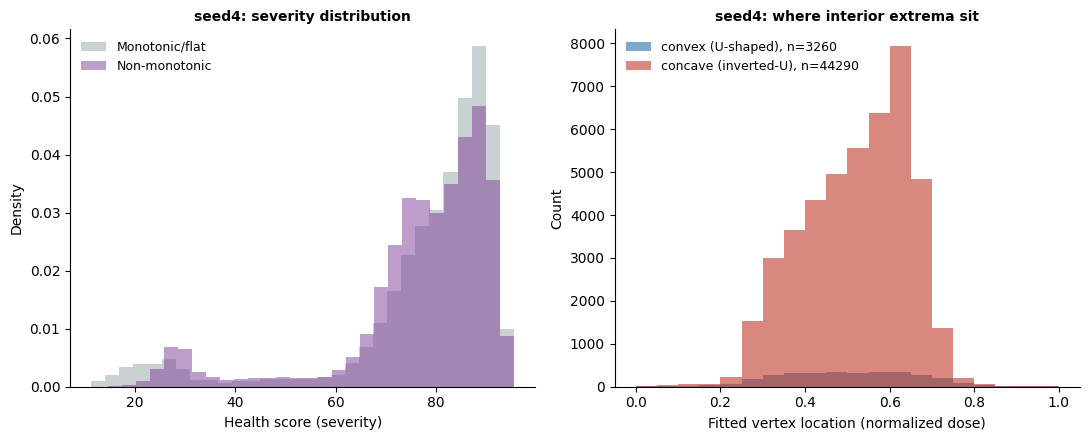

In [22]:
shape_overlap.analyze_non_monotonic_states = analyze_nm.analyze_non_monotonic_states
shape_overlap.get_actor_actions = action_dist.get_actor_actions

clinician_actions_test = processors['test'].rl_dataset["actions"]

results = shape_overlap.run_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['test'], clinician_actions_test,
    test_health_score, training_actions, training_health_score,
    save_dir=cql_model_dir,
)


=== Seed 0 (monotonic-increasing check) ===
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid point 5/20 (value=0.211)...
    grid point 6/20 (value=0.263)...
    grid point 7/20 (value=0.316)...
    grid point 8/20 (value=0.368)...
    grid point 9/20 (value=0.421)...
    grid point 10/20 (value=0.474)...
    grid point 11/20 (value=0.526)...
    grid point 12/20 (value=0.579)...
    grid point 13/20 (value=0.632)...
    grid point 14/20 (value=0.684)...
    grid point 15/20 (value=0.737)...
    grid point 16/20 (value=0.789)...
    grid point 17/20 (value=0.842)...
    grid point 18/20 (value=0.895)...
    grid point 19/20 (value=0.947)...
    grid point 20/20 (value=1.000)...
[seed0] 46697 non-monotonic timesteps out of 116662 (40.0%)
[seed0]  of non-monotonic: 7.3% convex (U-shaped), 92.7% concave (inverted-U)
[seed0]  99.0% have a genuine interior vertex (rest are edge-domin

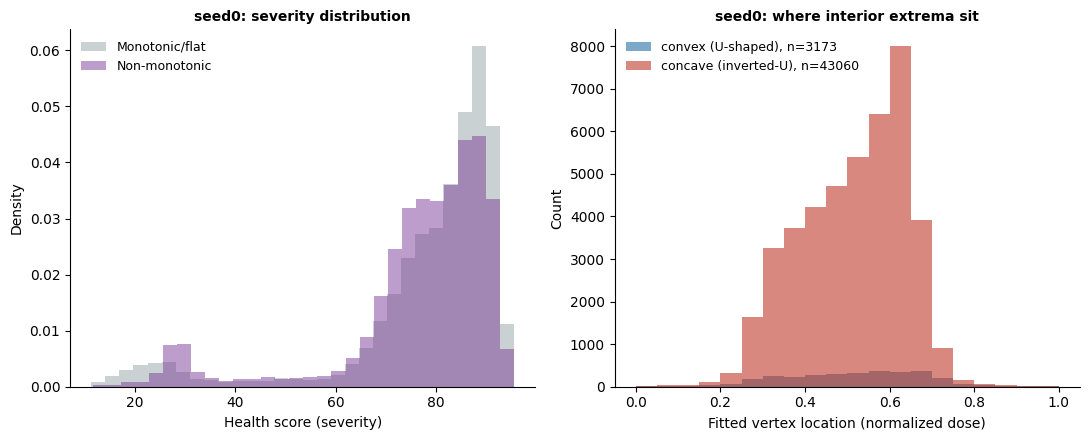

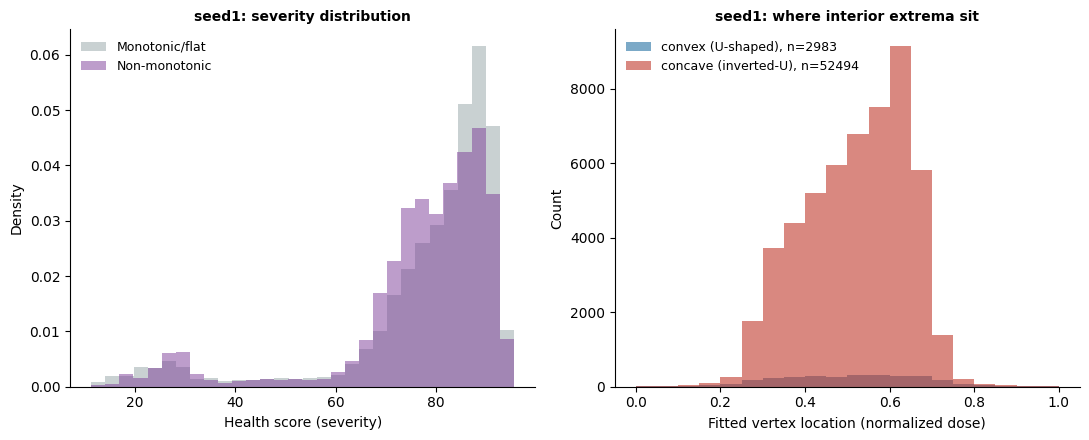

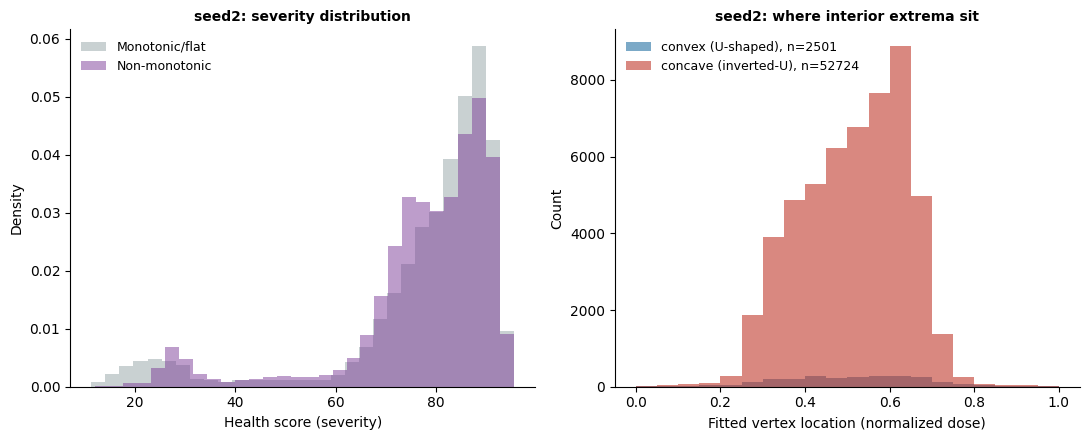

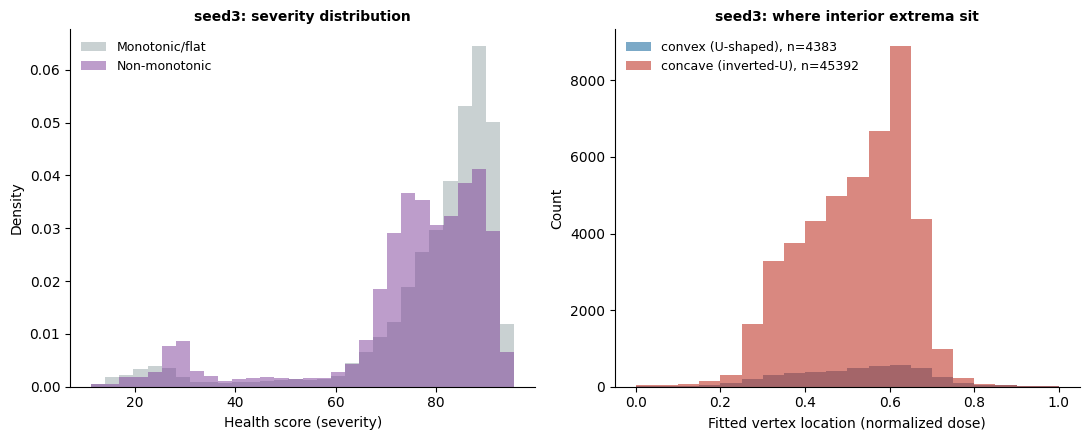

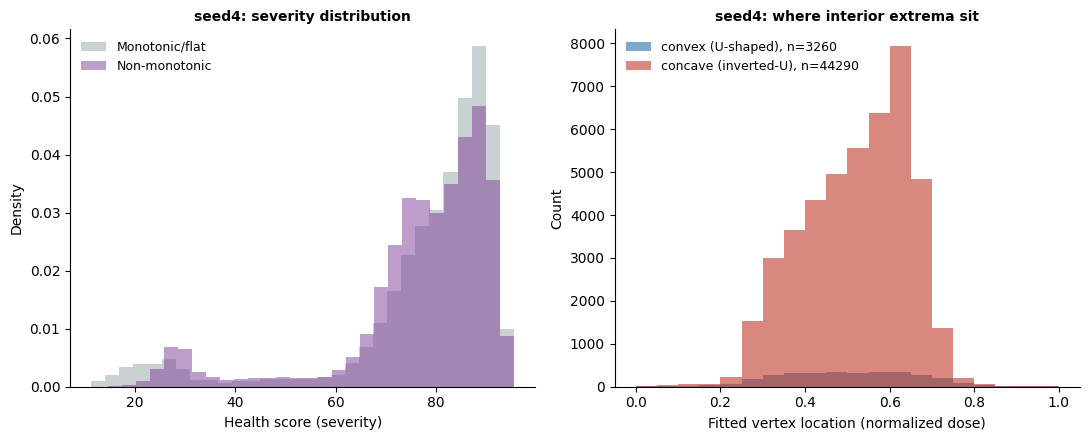

In [16]:
results_increasing = shape_overlap.run_monotonic_check_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['test'], clinician_actions_test,
    test_health_score, training_actions, training_health_score,
)

In [21]:
shape_overlap.action_sensitivity_sweep = analyze_nm.action_sensitivity_sweep
shape_overlap.classify_dose_response_shapes = analyze_nm.classify_dose_response_shapes
shape_overlap.build_joint_state_action_occupancy_counts = analyze_nm.build_joint_state_action_occupancy_counts
shape_overlap._bin_index = analyze_nm._bin_index

results_boundary = shape_overlap.run_boundary_occupancy_check_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['test'], clinician_actions_test,
    test_health_score, training_actions, training_health_score,
)


=== Seed 0 (boundary occupancy check) ===
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid point 5/20 (value=0.211)...
    grid point 6/20 (value=0.263)...
    grid point 7/20 (value=0.316)...
    grid point 8/20 (value=0.368)...
    grid point 9/20 (value=0.421)...
    grid point 10/20 (value=0.474)...
    grid point 11/20 (value=0.526)...
    grid point 12/20 (value=0.579)...
    grid point 13/20 (value=0.632)...
    grid point 14/20 (value=0.684)...
    grid point 15/20 (value=0.737)...
    grid point 16/20 (value=0.789)...
    grid point 17/20 (value=0.842)...
    grid point 18/20 (value=0.895)...
    grid point 19/20 (value=0.947)...
    grid point 20/20 (value=1.000)...
[seed0] Monotonically increasing states: 32367 (27.74%)
[seed0]   Of these, 58.0% have a well-supported (n>=10) dose combination AT the boundary (fluid=1.000)
[seed0]   Median training-data count at boundar

In [30]:
per_seed_data = shape_overlap.compute_extended_shape_data(
    cql_health_score_fixed_alpha_models,
    processors['test'], clinician_actions_test,
    test_health_score, training_actions, training_health_score,
)

shape_overlap.check_occupancy_by_category(per_seed_data)
shape_overlap.check_r2_and_vertex_occupancy_by_curvature(per_seed_data)
shape_overlap.check_flat_states(per_seed_data)

Computing extended shape data for seed 0...
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid point 5/20 (value=0.211)...
    grid point 6/20 (value=0.263)...
    grid point 7/20 (value=0.316)...
    grid point 8/20 (value=0.368)...
    grid point 9/20 (value=0.421)...
    grid point 10/20 (value=0.474)...
    grid point 11/20 (value=0.526)...
    grid point 12/20 (value=0.579)...
    grid point 13/20 (value=0.632)...
    grid point 14/20 (value=0.684)...
    grid point 15/20 (value=0.737)...
    grid point 16/20 (value=0.789)...
    grid point 17/20 (value=0.842)...
    grid point 18/20 (value=0.895)...
    grid point 19/20 (value=0.947)...
    grid point 20/20 (value=1.000)...
Computing extended shape data for seed 1...
    grid point 1/20 (value=0.000)...
    grid point 2/20 (value=0.053)...
    grid point 3/20 (value=0.105)...
    grid point 4/20 (value=0.158)...
    grid poin

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/shape_breakdown_figure.png

=== Pooled category counts (all 5 seeds combined) ===
  Increasing: n=164499 (28.20%), median health score=80.4
  Decreasing: n=161575 (27.70%), median health score=85.5
  Concave (inverted-U): n=239521 (41.06%), median health score=79.5
  Convex (U-shaped): n=17554 (3.01%), median health score=87.2
  Flat: n=161 (0.03%), median health score=89.0


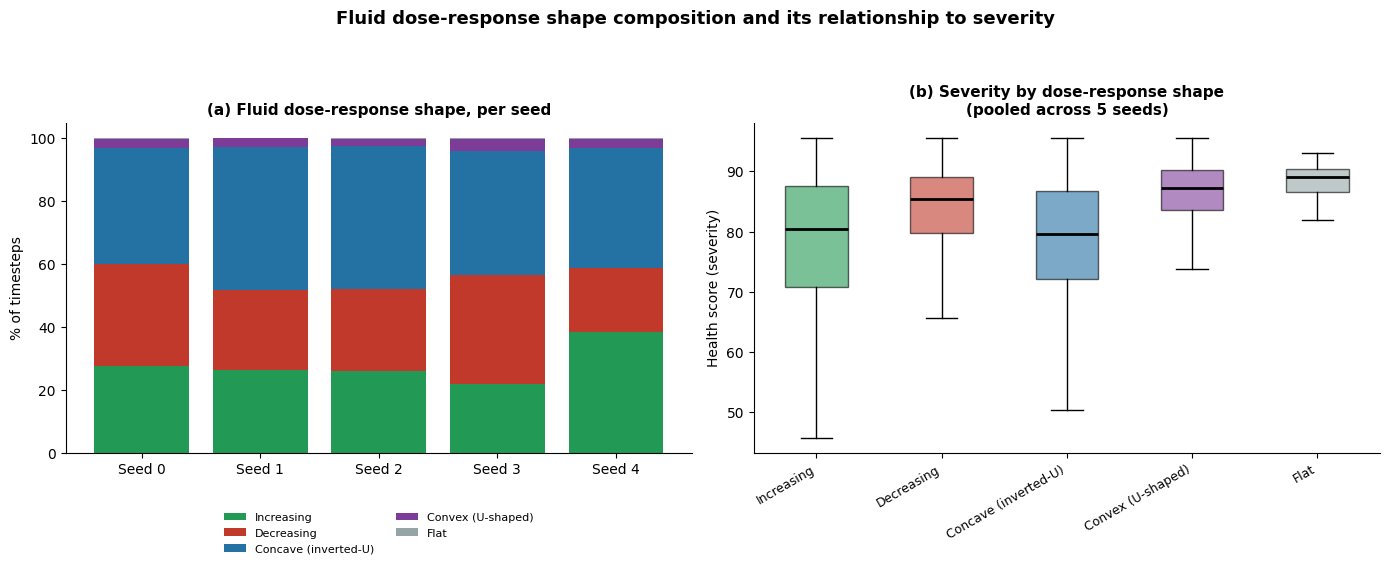

In [31]:
per_seed_category = [d["category"] for d in per_seed_data]
per_seed_hs = [d["health_score"] for d in per_seed_data]

fig = shape_overlap.plot_shape_breakdown_figure(
    per_seed_category, per_seed_hs,
    save_path=os.path.join(cql_model_dir, "shape_breakdown_figure.png"),
)
fig

"The residual high-dose fluid recommendations were substantially explained by a genuinely monotonically-increasing critic dose-response for the relevant states (~50-64% overlap across seeds), rather than by non-monotonic (U-shaped) structure. However, only 56-61% of these monotonically-increasing states had genuine training-data support for the maximal dose at their matching severity level, with the remainder relying on some degree of extrapolation beyond the range of doses actually observed for comparably severe patients. This indicates the residual extreme-dose behavior reflects a mixture of a real, moderately data-grounded subpopulation and a smaller degree of unsupported extrapolation, reinforcing the case for a data-support-based safety flag (Section [X]) rather than treating any specific dose recommendation as uniformly trustworthy."

In [33]:
shape_overlap.check_all_categories_inferred_point_occupancy(
    per_seed_data,
    training_actions, training_health_score,
    test_health_score, clinician_actions_test,
)

=== Occupancy support at the CRITIC-IMPLIED point of interest, by category ===
(Increasing/Decreasing: at the swept boundary. Concave/Convex: at the fitted vertex.)
  Increasing (at fluid=1 boundary): n=164499, median count=29, mean count=39.2, %>=10=83.9%
  Decreasing (at fluid=0 boundary): n=161575, median count=2850, mean count=2898.6, %>=10=100.0%
  Concave (at vertex): n=237960, median count=3361, mean count=3386.1, %>=10=100.0%
  Convex (at vertex): n=16300, median count=2852, mean count=3150.6, %>=10=100.0%


"Dose-response shape analysis and the reliability of extreme-dose recommendations

To characterize the CQL critic's fluid dose-response beyond aggregate action-sensitivity, we classified the shape of Q(fluid dose) at every test-set state, holding vasopressor at its real, clinician-administered dose. For each state, Q was evaluated across a 20-point grid spanning the fluid dose range, and the resulting curve was classified as monotonically increasing or decreasing (Spearman correlation ρ ≥ 0.8 in the respective direction), flat (total variation across the sweep below 5% of the critic's own Q range), or non-monotonic. Non-monotonic curves were further split into concave (inverted-U, a genuine interior optimum) or convex (U-shaped, worse in the middle) via the sign of a fitted quadratic's leading coefficient. This analysis was repeated independently for each of the five final seeds (alpha=0.006), pooling test-set states across seeds for the summary statistics reported below.

Pooling across seeds, fluid dose-response was classified as concave (inverted-U) for 41.1% of states, increasing for 28.2%, decreasing for 27.7%, convex (U-shaped) for 3.0%, and flat for 0.03%. Median severity (health score) differed systematically by category: increasing (median 80.4) and concave (79.5) states were concentrated among sicker patients, while decreasing (85.5), convex (87.2), and flat (89.0) states skewed toward healthier patients — consistent with a clinically plausible pattern in which sicker patients are more likely to benefit from additional fluid, while healthier patients are better served by lower doses. Flat states, though rare, were confirmed to correspond to a small subpopulation of healthy patients essentially never given fluid in practice (median health score 89.0 vs. 82.3 for all other states).

We then asked whether each category's implied recommendation was backed by genuine training-data support, using the same joint (severity × fluid dose × vasopressor dose) occupancy framework applied elsewhere in this work. For monotonic categories, we evaluated occupancy at the swept boundary implied by the shape (fluid=1 for increasing, fluid=0 for decreasing); for non-monotonic categories, we evaluated occupancy at the fitted quadratic's vertex. Decreasing, concave, and convex categories were all robustly supported, with essentially all states (100%, 100%, and 100% respectively) meeting our minimum-count threshold and median training-set counts in the thousands. Increasing states were a striking outlier: only 83.9% met the minimum-count threshold, with a median supporting count of just 29 — one to two orders of magnitude lower than every other category. This asymmetry indicates that "more fluid is beneficial" conclusions are systematically less well-grounded in the training data than any other type of dose-response conclusion this critic reaches, and directly explains the residual near-maximal fluid dose recommendations documented in Section [X]: rather than reflecting a rare, anomalous critic pathology (e.g., U-shaped extrapolation, which we show here is in fact well-supported), these recommendations disproportionately originate from the one category of states where the critic's implied action rests on comparatively little real-world precedent.

This finding reinforces the case for the data-support-based safety mechanism proposed in Section [Y]: rather than treating all model recommendations as uniformly reliable, flagging the specific, quantifiable subset of low-support recommendations — concentrated, as shown here, among a minority of high-severity states with a monotonically increasing dose-response — offers a targeted and empirically grounded approach to safe deployment."

Fill in [X]/[Y] for your actual section references. Two things worth double-checking before finalizing: (1) confirm the exact rho_threshold/flat_range_pct/n_severity_bins/min_count values you used match what I've stated (I used your established defaults — 0.8, 5%, 20, 10 — but worth a final check against your actual notebook calls); (2) I described this as pooling test-set states "across seeds" for the headline percentages — worth deciding whether you want to also report the per-seed range (min-max across the 5 seeds) for the two or three most important numbers (the 28.2% increasing figure, and the 29-vs-thousands occupancy contrast) for extra rigor, consistent with how you've reported seed variability elsewhere in this paper.

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/example_dose_response_curves.png


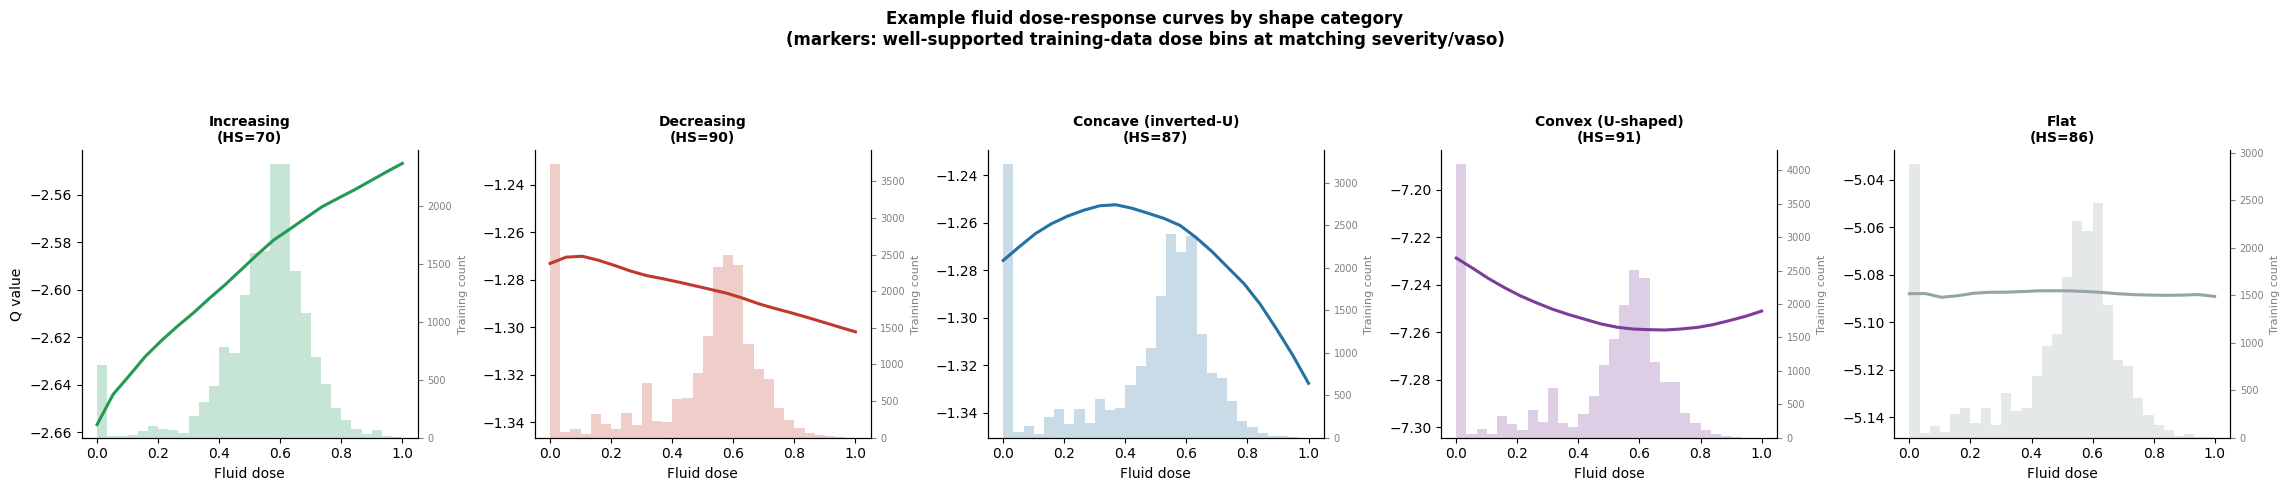

In [47]:
fig = shape_overlap.plot_example_dose_response_curves(
    cql_health_score_fixed_alpha_models[0],
    processors['test'], clinician_actions_test,
    per_seed_data, 0,
    training_actions, training_health_score,
    save_path=os.path.join(cql_model_dir, "example_dose_response_curves.png"),
)
fig

Methodology (for above figure)

For each of the five dose-response shape categories, we selected one representative test-set state — for Concave and Convex, the state with the highest quadratic fit R² (the cleanest, most unambiguous example of that curvature); for Increasing, Decreasing, and Flat, a state drawn at random, since no equivalent fit-quality metric applies to monotonic or flat classifications. For the selected state, Q(fluid dose) was recomputed across the full [0,1] dose grid, holding vasopressor at that state's own real, clinician-administered dose — the same convention used throughout this dose-response analysis. To visualize whether this curve's shape is consistent with genuine data support, we overlaid a histogram of the real, training-set fluid doses administered to a broader comparison group: all training-set timesteps falling in the same severity (health-score) bin as the example state, and matching its vasopressor-fired status (fired vs. not fired), using the same binning scheme as our occupancy-support analysis elsewhere in this work.

We note that this comparison is not a strict like-for-like test: the Q curve is specific to a single state (including its full state representation beyond severity and vasopressor status), while the overlaid dose histogram reflects a coarser grouping — all training patients sharing that state's severity bin and vasopressor status, not that exact state. As such, this figure should be read as an illustrative, approximate check of plausibility (does the curve's shape broadly align with where the training data's dosing mass lies for comparable patients) rather than a formal occupancy statistic for that specific state; the latter is reported precisely, at the individual-state level, in our systematic occupancy-support analysis (Section [X]).